In [1]:
import os
import glob
import pandas as pd
import numpy as np
import pypsa
import matplotlib.pyplot as plt

In [2]:
# look at 2050 - use year filter that is used in visualizations

# 1. Point to the results folder
RESULTS_DIR = "results"
# Define final summary spreadsheet
OUTPUT_CSV = "presentation_metrics_summary.csv"

In [4]:
# Find every solved NetCDF (.nc) scenario file we generated
network_files = sorted(glob.glob(os.path.join(RESULTS_DIR, "*.nc")))

print(f"Found and processing {len(network_files)} solved network files...")

# Empty container list to hold extracted data 
metrics_list = []

# Define the invesemtn years
years = [2025, 2030, 2040, 2050]

# Scenario iteration loop
# Loop through each solved scenario 
for filepath in network_files:
    filename = os.path.basename(filepath)
    try:
        # Load the optimized network into memory
        n = pypsa.Network(filepath)
    except Exception as e:
        print(f"Skipping {filename}: {e}")
        continue
    # Use the filename as the scenario name
    scen_name = filename.replace(".nc", "")
    for y in years:
    # Grab snapshot weights
    # Multiplying by wiehgts converts MW into MWh over time 
        weights = n.snapshot_weightings.generators


    # -------------------------------------------------------------
    # Analyze Hydrogen Production Mix (green vs blue vs grey)
    # -------------------------------------------------------------
    # Identify hydrogen-producing links
        green_h2_mwh = 0.0
        blue_h2_mwh = 0.0
        grey_h2_mwh = 0.0
    
        for link in n.links.index:
            bus1 = str(n.links.loc[link, "bus1"]) if "bus1" in n.links.columns else ""
            link_lower = link.lower()

        # Check link name 
            carrier = str(n.links.loc[link, "carrier"]) if "carrier" in n.links.columns else ""
            carrier_lower = carrier.lower()

            is_hydrogen_link = (
                bus1.lower() == "hydrogen" or 
                "hydrogen" in link_lower or 
                "smr" in link_lower or "smr" in carrier_lower or
                "electrolysis" in link_lower or "electrolysis" in carrier_lower
        )

            if is_hydrogen_link:
                prod_mwh = abs((n.links_t.p1[link] * weights).sum())


                if "electrolysis" in link_lower or "electrolysis" in carrier_lower:
                    green_h2_mwh += prod_mwh
                elif "ccs" in link_lower or "ccs" in carrier_lower:
                    blue_h2_mwh += prod_mwh
                else:
                    grey_h2_mwh += prod_mwh

        total_h2_mwh = green_h2_mwh + blue_h2_mwh + grey_h2_mwh

    # Calculate percentage shares    
        green_share = (green_h2_mwh / total_h2_mwh * 100) if total_h2_mwh > 0 else 0
        blue_share = (blue_h2_mwh / total_h2_mwh * 100) if total_h2_mwh > 0 else 0
        grey_share = (grey_h2_mwh / total_h2_mwh * 100) if total_h2_mwh > 0 else 0

    # -------------------------------------------------------------
    # Electricity Conversion Mix and Electrolysis Load
    # -------------------------------------------------------------
        elec_gen = {}

        if "Electricity" in n.buses.index:
            elec_gens = n.generators[n.generators.bus == "Electricity"].index
            for gen in elec_gens:
                carrier = str(n.generators.loc[gen, "carrier"])
                prod = (n.generators_t.p[gen] * weights).sum()
                elec_gen[carrier] = elec_gen.get(carrier, 0) + prod

    # Links feeding Electricity bus (e.g., CCGT, Biomass, Nuclear)
        for link in n.links.index:
            if n.links.loc[link, "bus1"] == "Electricity":
                carrier = str(n.links.loc[link, "carrier"]) if "carrier" in n.links.columns else link
                prod = abs((n.links_t.p1[link] * weights).sum())
                elec_gen[carrier] = elec_gen.get(carrier, 0) + prod   
    

        total_elec_mwh = sum(elec_gen.values())

    #Group the conversion technologies supplying the electricity 
        fossil_elec_mwh = sum(v for k, v in elec_gen.items() if any(f in k.lower() for f in ["ccgt", "gas", "fossil"]))
        renewable_elec_mwh = sum(v for k, v in elec_gen.items() if any(r in k.lower() for r in ["wind", "solar", "pv", "biomass"]))
        nuclear_elec_mwh = sum(v for k, v in elec_gen.items() if "nuclear" in k.lower())

    # Measure how much electricity is pulled out of the grid to feed electrolysis 
        elec_to_h2_mwh = 0.0
        for link in n.links.index:
            link_lower = link.lower()
            carrier_lower = str(n.links.loc[link, "carrier"]).lower() if "carrier" in n.links.columns else ""
            if "electrolysis" in link.lower() or "electrolysis" in carrier_lower:
                elec_to_h2_mwh += abs((n.links_t.p0[link] * weights).sum())

    # Calculate what percentage of total grid electricity generation is taken by electrolysis 
        electrolysis_load_share = (elec_to_h2_mwh / total_elec_mwh * 100) if total_elec_mwh > 0 else 0

    # -------------------------------------------------------------
    # How green is the green hydrogen really? (Cabron intensity of electrolysis)
    # -------------------------------------------------------------
    # Calculate the exact hourly carbon footprint of the electicty consumbed by the electrolyzers 
        total_fossil_emissions_t = 0.0

    # Looking at CCGT links to calculate emissions
        for link in n.links.index:
            if n.links.loc[link, "bus1"] == "Electricity" and any(f in link.lower() for f in ["ccgt", "gas"]):
                # Efficiency lookup (default to 0.5 if not specified)
                eff = n.links.loc[link, 'efficiency'] if 'efficiency' in n.links.columns and n.links.loc[link, 'efficiency'] > 0 else 0.50
                co2_factor = 0.2  # tCO2 per MWh thermal input
                
                # Gas thermal input = Electrical output / Efficiency
                elec_output = abs(n.links_t.p1[link] * weights)
                thermal_input = elec_output / eff
                total_fossil_emissions_t += (thermal_input * co2_factor).sum()


        # Carbon Intensity = total power sector emissions (t) / total electrolysis electricity demand (MWh)
        # Multiplied by 1000 to convert tonnes into kg of CO2 per MWh of electricity used
        if elec_to_h2_mwh > 0 and total_fossil_emissions_t > 0:
            electrolysis_carbon_intensity = (total_fossil_emissions_t / total_elec_mwh) * 1000
        else:
            electrolysis_carbon_intensity = 0.0

        # Extract total system optimization cost from the objective function (converted to billions of euros)
        system_cost_billion_eur = n.objective / 1e9 if hasattr(n, "objective") else np.nan
    
        # Cumulative CO2 emissions (check if it's named 'CO2 atmosphere' or just 'CO2' in your topology)
        cum_co2_mt = np.nan
        if "CO2 atmosphere" in n.stores.index:
            cum_co2_mt = n.stores_t.e["CO2 atmosphere"].iloc[-1] / 1e6  # Convert to MtCO2
        elif "CO2 storage" in n.stores.index:
            cum_co2_mt = n.stores_t.e["CO2"].iloc[-1] / 1e6

        # Record metrics
        # Store all calculated indicators
        metrics_list.append({
            "Scenario": scen_name,
            "Year":y,
            "Total_H2_TWh": round(total_h2_mwh / 1e6, 2),
            "Green_H2_Pct": round(green_share, 2),
            "Blue_H2_Pct": round(blue_share, 2),
            "Grey_H2_Pct": round(grey_share, 2),
            "Total_Elec_Gen_TWh": round(total_elec_mwh / 1e6, 2),
            "Fossil_Elec_TWh": round(fossil_elec_mwh / 1e6, 2),
            "Renewable_Elec_TWh": round(renewable_elec_mwh / 1e6, 2),
            "Nuclear_Elec_TWh": round(nuclear_elec_mwh / 1e6, 2),
            "Electrolysis_Power_Demand_TWh": round(elec_to_h2_mwh / 1e6, 2),
            "Electrolysis_Load_Share_Pct": round(electrolysis_load_share, 2),
            "Electrolysis_Carbon_Intensity_kgCO2_MWh": round(electrolysis_carbon_intensity, 2),
            "Total_System_Cost_Billion_EUR": round(system_cost_billion_eur, 2),
            "Cumulative_CO2_Mt": round(cum_co2_mt, 2)
    })

# Convert the collected list of scenario dictionaries into a DataFrame
df_summary = pd.DataFrame(metrics_list)

# Explicitly clean up any zero-demand carbon intensities to prevent 1e18 scientific notation
df_summary["Electrolysis_Carbon_Intensity_kgCO2_MWh"] = df_summary["Electrolysis_Carbon_Intensity_kgCO2_MWh"].fillna(0.0)
df_summary.loc[df_summary["Electrolysis_Power_Demand_TWh"] == 0.0, "Electrolysis_Carbon_Intensity_kgCO2_MWh"] = 0.0

# Export the dataframe to a CSV file so it can be plotted or used in presentation
df_summary.to_csv(OUTPUT_CSV, index=False)

print(f"\nSUCCESS: Statistics exported to '{OUTPUT_CSV}'")

# Display preview of the summary table
display(df_summary.head(10))

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)


Found and processing 27 solved network files...


INFO:pypsa.network.io:Imported network 'carbon_price_0' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_100' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_125' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_150' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'carbon_price_175' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New


SUCCESS: Statistics exported to 'presentation_metrics_summary.csv'


,Scenario,Year,Total_H2_TWh,Green_H2_Pct,Blue_H2_Pct,Grey_H2_Pct,Total_Elec_Gen_TWh,Fossil_Elec_TWh,Renewable_Elec_TWh,Nuclear_Elec_TWh,Electrolysis_Power_Demand_TWh,Electrolysis_Load_Share_Pct,Electrolysis_Carbon_Intensity_kgCO2_MWh,Total_System_Cost_Billion_EUR,Cumulative_CO2_Mt
0,carbon_price_0,2025,102.5,0.00,0.00,100.00,183.54,2.45,181.09,0.0,0.00,0.00,0.00,2343.67,269.76
1,carbon_price_0,2030,102.5,0.00,0.00,100.00,183.54,2.45,181.09,0.0,0.00,0.00,0.00,2343.67,269.76
2,carbon_price_0,2040,102.5,0.00,0.00,100.00,183.54,2.45,181.09,0.0,0.00,0.00,0.00,2343.67,269.76
3,carbon_price_0,2050,102.5,0.00,0.00,100.00,183.54,2.45,181.09,0.0,0.00,0.00,0.00,2343.67,269.76
4,carbon_price_100,2025,102.5,0.02,1.35,98.63,218.90,1.58,217.32,0.0,0.03,0.01,2.41,2532.65,249.26
5,carbon_price_100,2030,102.5,0.02,1.35,98.63,218.90,1.58,217.32,0.0,0.03,0.01,2.41,2532.65,249.26
6,carbon_price_100,2040,102.5,0.02,1.35,98.63,218.90,1.58,217.32,0.0,0.03,0.01,2.41,2532.65,249.26
7,carbon_price_100,2050,102.5,0.02,1.35,98.63,218.90,1.58,217.32,0.0,0.03,0.01,2.41,2532.65,249.26
8,carbon_price_125,2025,102.5,0.02,77.36,22.63,235.78,1.37,234.41,0.0,0.03,0.01,1.94,2574.23,224.03
9,carbon_price_125,2030,102.5,0.02,77.36,22.63,235.78,1.37,234.41,0.0,0.03,0.01,1.94,2574.23,224.03


Looking at the fuel mix on an hourly basis and asks: 

- How much fossil generatin is running? 
    - Looking at all CCGT plants supplying electricity 
- How much co2 did they emit? 
    - By dividng by a gas emission factor, we calculate the total tonnes of co2 emisste by the power sector 
- What is the carbon intensity? 
    - We devide those total power sector emissions by the total electricty demanded by electrolysis. This gives us kg co2 emitted per MWh of electricity consumed by electrolysis 

,Scenario,Year,Total_H2_TWh,Green_H2_Pct,Blue_H2_Pct,Grey_H2_Pct,Total_Elec_Gen_TWh,Fossil_Elec_TWh,Renewable_Elec_TWh,Nuclear_Elec_TWh,Electrolysis_Power_Demand_TWh,Electrolysis_Load_Share_Pct,Electrolysis_Carbon_Intensity_kgCO2_MWh,Total_System_Cost_Billion_EUR,Cumulative_CO2_Mt
3,carbon_price_0,2050,102.5,0.00,0.00,100.00,183.54,2.45,181.09,0.0,0.00,0.00,0.00,2343.67,269.76
7,carbon_price_100,2050,102.5,0.02,1.35,98.63,218.90,1.58,217.32,0.0,0.03,0.01,2.41,2532.65,249.26
11,carbon_price_125,2050,102.5,0.02,77.36,22.63,235.78,1.37,234.41,0.0,0.03,0.01,1.94,2574.23,224.03
15,carbon_price_150,2050,102.5,0.02,99.96,0.02,280.50,1.13,279.37,0.0,0.03,0.01,1.34,2613.22,206.27
19,carbon_price_175,2050,102.5,0.02,99.96,0.02,309.79,0.72,309.07,0.0,0.03,0.01,0.77,2649.26,197.25


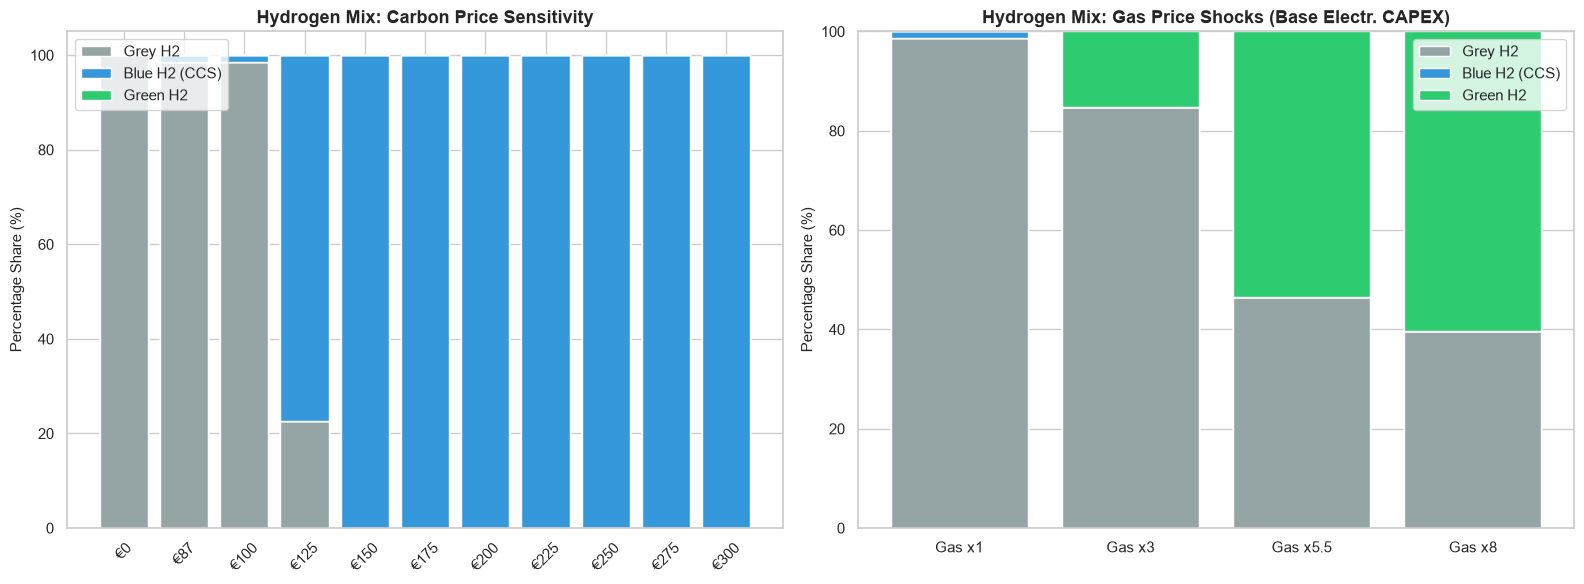

/var/folders/_y/0g41cdc52svdnkt35_8c01pw0000gn/T/ipykernel_40784/640240640.py:99: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/_y/0g41cdc52svdnkt35_8c01pw0000gn/T/ipykernel_40784/640240640.py:100: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig('figure2_green_hydrogen_details.png', dpi=300)
/Users/sabinewittmann/micromamba/envs/mt-env/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


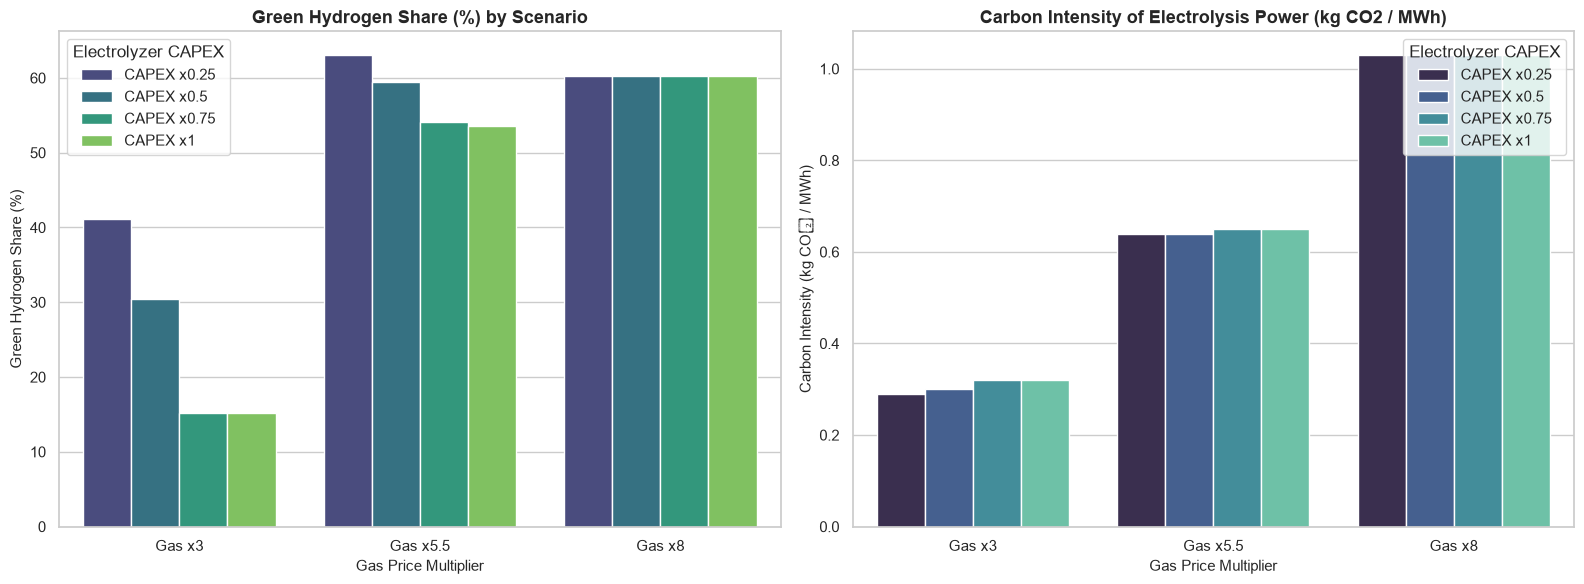

SUCCESS: Both figures successfully generated and saved!


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the summary metrics
df = pd.read_csv('presentation_metrics_summary.csv')
sns.set_theme(style="whitegrid")

df_2050 = df[df['Year']==2050]

display(df_2050.head())

# ==============================================================
# FIGURE 1: Hydrogen Mix (Carbon Price Sensitivity & Gas Price Shocks)
# ==============================================================
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel A: Carbon Price Sensitivity ---
df_carbon = df[df['Scenario'].str.startswith('carbon_price')].copy()
df_carbon['sort_val'] = df_carbon['Scenario'].apply(lambda s: int(s.split('_')[-1]) if s.split('_')[-1].isdigit() else 0)
df_carbon = df_carbon.sort_values('sort_val')
df_carbon['Scenario_Label'] = df_carbon['Scenario'].str.replace('carbon_price_', '€')

scenarios_c = df_carbon['Scenario_Label']
axes1[0].bar(scenarios_c, df_carbon['Grey_H2_Pct'], label='Grey H2', color='#95a5a6')
axes1[0].bar(scenarios_c, df_carbon['Blue_H2_Pct'], bottom=df_carbon['Grey_H2_Pct'], label='Blue H2 (CCS)', color='#3498db')
axes1[0].bar(scenarios_c, df_carbon['Green_H2_Pct'], bottom=df_carbon['Grey_H2_Pct']+df_carbon['Blue_H2_Pct'], label='Green H2', color='#2ecc71')
axes1[0].set_title('Hydrogen Mix: Carbon Price Sensitivity', fontsize=13, fontweight='bold')
axes1[0].set_ylabel('Percentage Share (%)', fontsize=11)
axes1[0].tick_params(axis='x', rotation=45)
axes1[0].legend(loc='upper left', frameon=True)

# --- Panel B: Gas Price Shocks (Base CAPEX elec_x1) ---
df_gas_subset = df[df['Scenario'].str.startswith('gas') & df['Scenario'].str.endswith('_elec_x1')].copy()
# Sort by gas multiplier value
df_gas_subset['sort_val'] = df_gas_subset['Scenario'].apply(lambda s: float(s.split('_')[1].replace('x', '')))
df_gas_subset = df_gas_subset.sort_values('sort_val')

scenarios_g = df_gas_subset['Scenario'].str.replace('gas_x', 'Gas x').str.replace('_elec_x1', '')
axes1[1].bar(scenarios_g, df_gas_subset['Grey_H2_Pct'], label='Grey H2', color='#95a5a6')
axes1[1].bar(scenarios_g, df_gas_subset['Blue_H2_Pct'], bottom=df_gas_subset['Grey_H2_Pct'], label='Blue H2 (CCS)', color='#3498db')
axes1[1].bar(scenarios_g, df_gas_subset['Green_H2_Pct'], bottom=df_gas_subset['Grey_H2_Pct']+df_gas_subset['Blue_H2_Pct'], label='Green H2', color='#2ecc71')
axes1[1].set_title('Hydrogen Mix: Gas Price Shocks (Base Electr. CAPEX)', fontsize=13, fontweight='bold')
axes1[1].set_ylabel('Percentage Share (%)', fontsize=11)
axes1[1].tick_params(axis='x', rotation=0)
axes1[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('figure1_hydrogen_mix.png', dpi=300)
plt.show()


# ==============================================================
# FIGURE 2: Green Hydrogen Share & Carbon Intensity (Gas & CAPEX)
# ==============================================================
df_active = df[df['Scenario'].str.startswith('gas') & (df['Green_H2_Pct'] > 0)].copy()

def parse_scen(scen):
    parts = scen.split('_')
    gas = parts[1].replace('x', 'Gas x')
    capex = parts[3].replace('x', 'CAPEX x')
    return gas, capex

df_active[['Gas_Scenario', 'Capex_Scenario']] = pd.DataFrame(
    df_active['Scenario'].apply(parse_scen).tolist(), 
    index=df_active.index
)

fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel A: Green Hydrogen Share (%) ---
sns.barplot(
    data=df_active,
    x='Gas_Scenario',
    y='Green_H2_Pct',
    hue='Capex_Scenario',
    palette='viridis',
    ax=axes2[0]
)
axes2[0].set_title('Green Hydrogen Share (%) by Scenario', fontsize=13, fontweight='bold')
axes2[0].set_xlabel('Gas Price Multiplier', fontsize=11)
axes2[0].set_ylabel('Green Hydrogen Share (%)', fontsize=11)
axes2[0].legend(title='Electrolyzer CAPEX', loc='upper left')

# --- Panel B: Carbon Intensity of Electrolysis Power ---
sns.barplot(
    data=df_active,
    x='Gas_Scenario',
    y='Electrolysis_Carbon_Intensity_kgCO2_MWh',
    hue='Capex_Scenario',
    palette='mako',
    ax=axes2[1]
)
axes2[1].set_title('Carbon Intensity of Electrolysis Power (kg CO2 / MWh)', fontsize=13, fontweight='bold')
axes2[1].set_xlabel('Gas Price Multiplier', fontsize=11)
axes2[1].set_ylabel('Carbon Intensity (kg CO₂ / MWh)', fontsize=11)
axes2[1].legend(title='Electrolyzer CAPEX', loc='upper right')

plt.tight_layout()
plt.savefig('figure2_green_hydrogen_details.png', dpi=300)
plt.show()

print("SUCCESS: Both figures successfully generated and saved!")

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


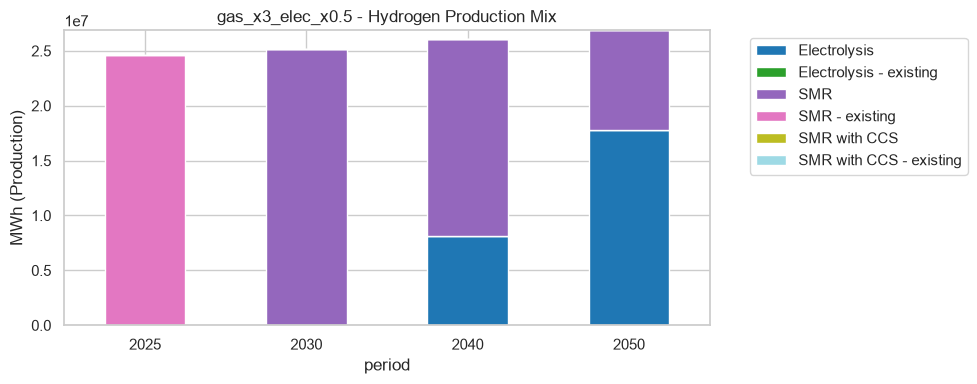

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x8_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


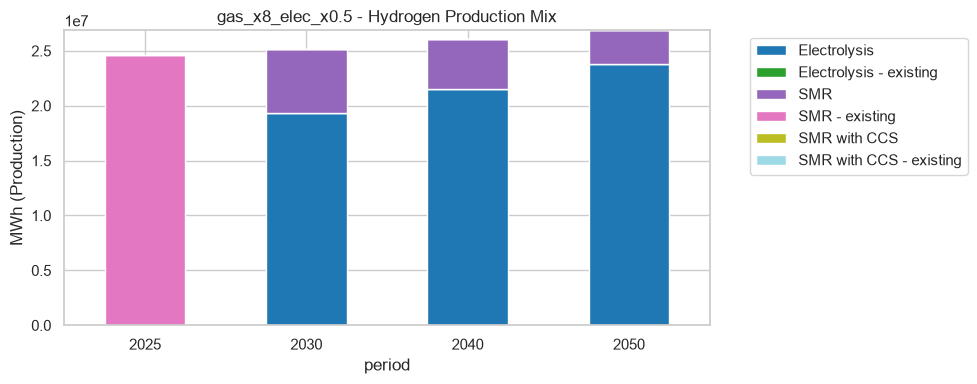

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x5.5_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


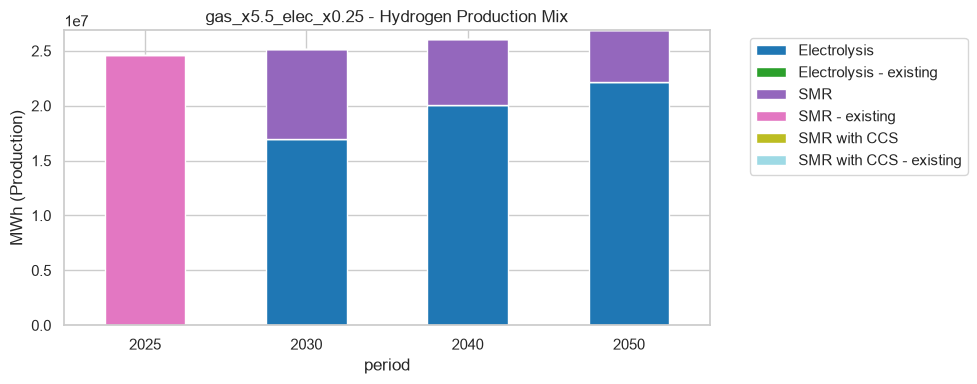

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


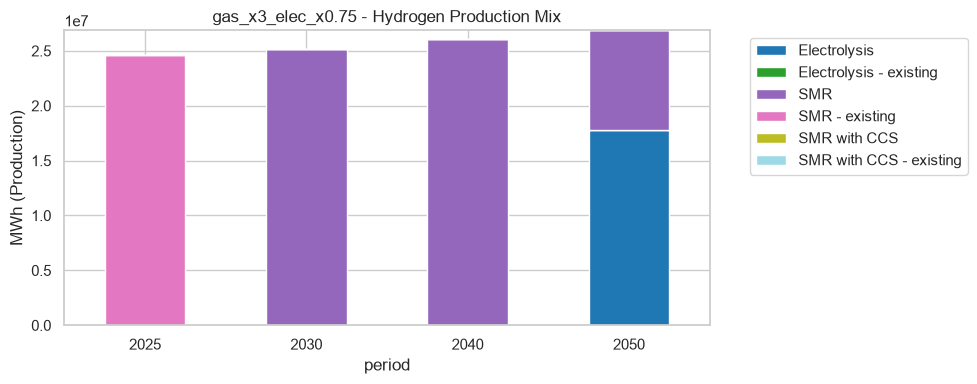

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x5.5_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


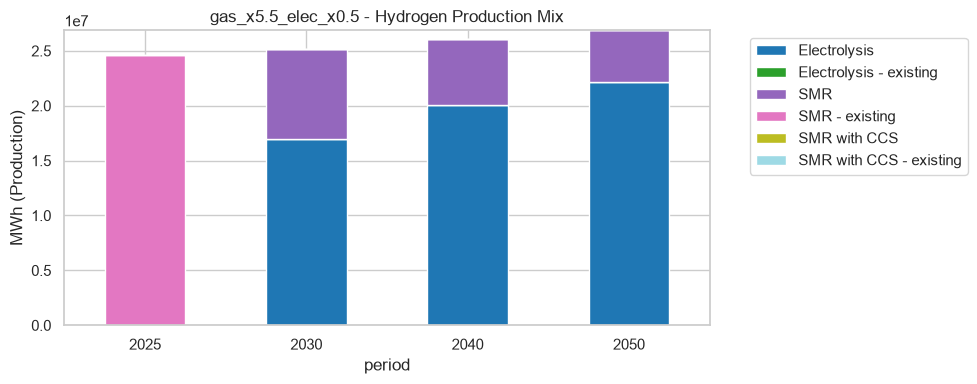

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x8_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


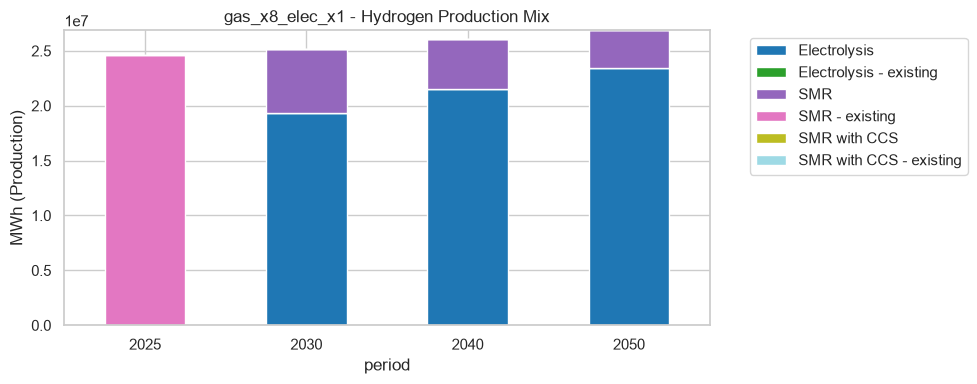

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x5.5_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


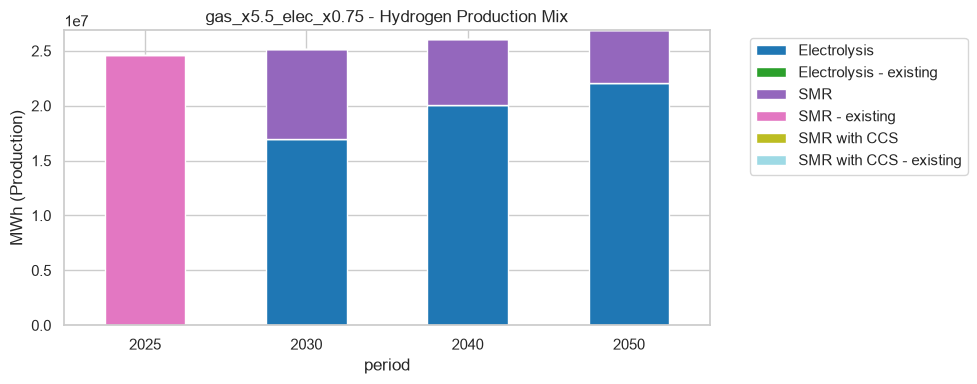

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


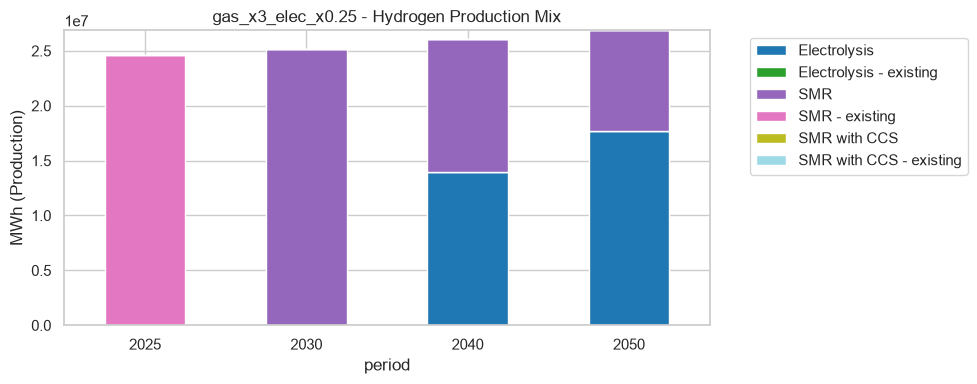

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


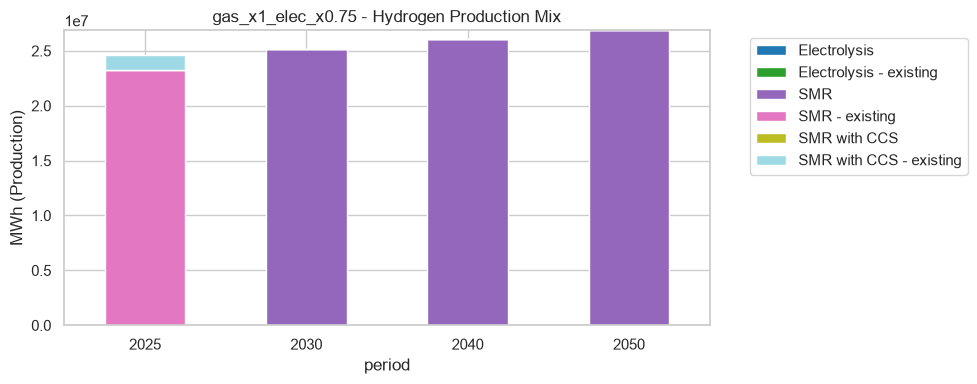

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


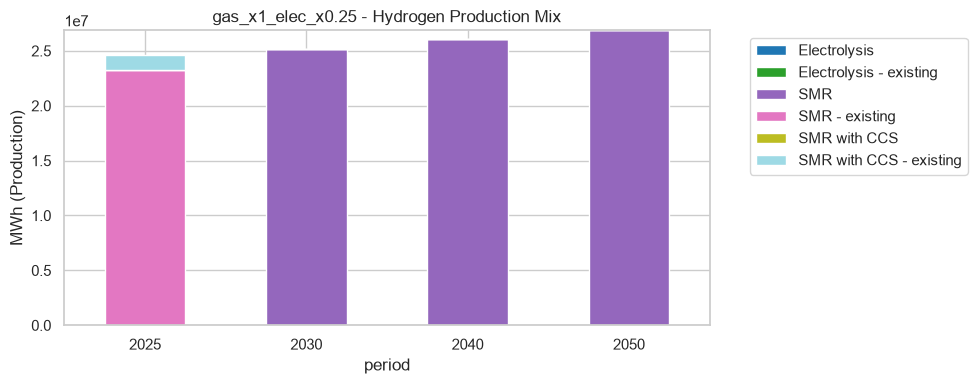

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x5.5_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


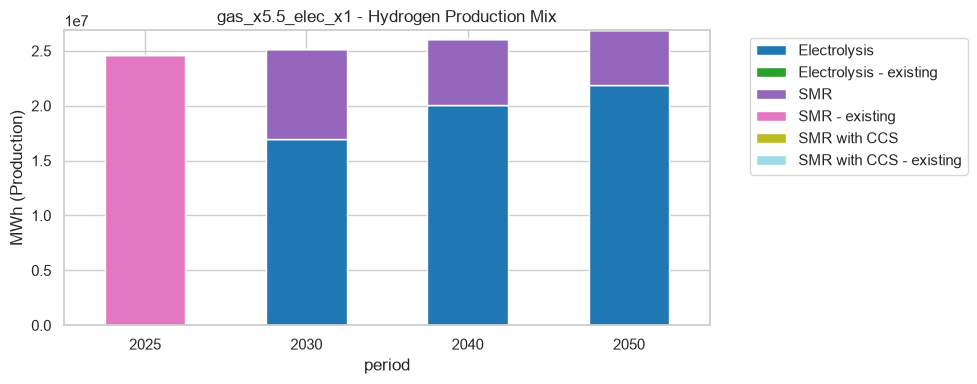

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


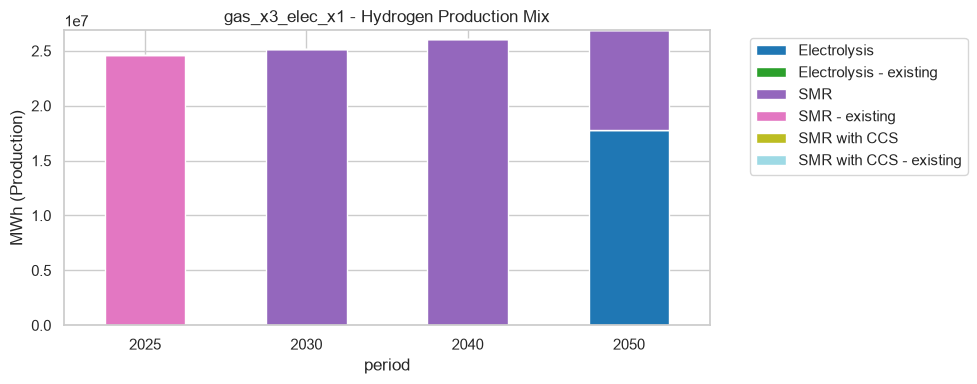

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x8_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


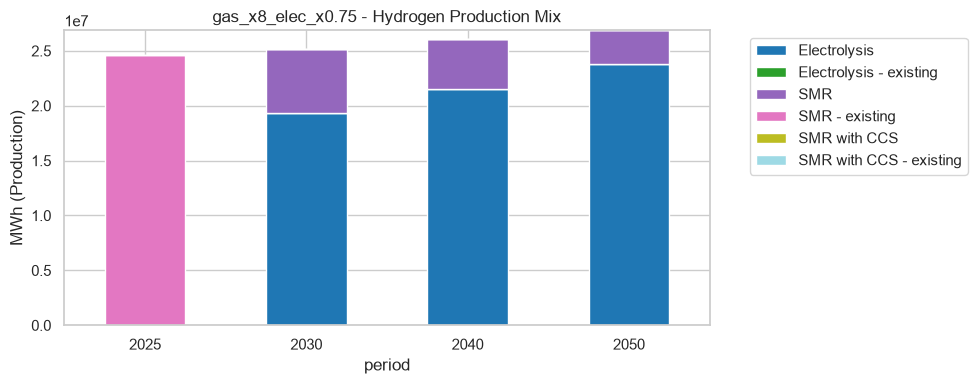

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x8_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


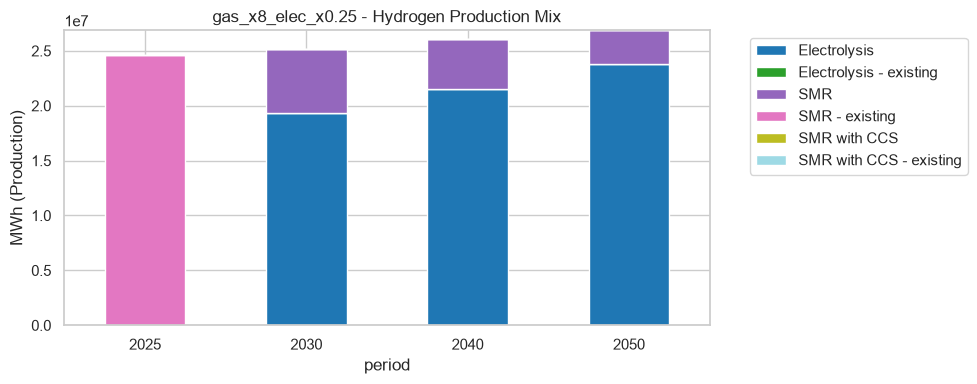

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


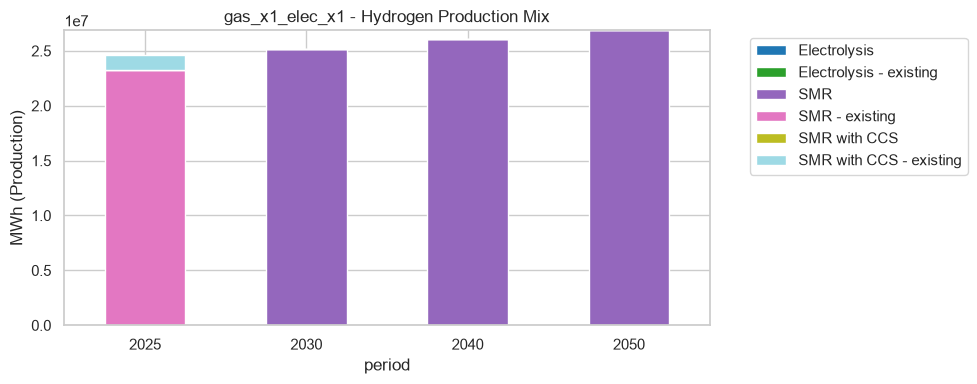

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


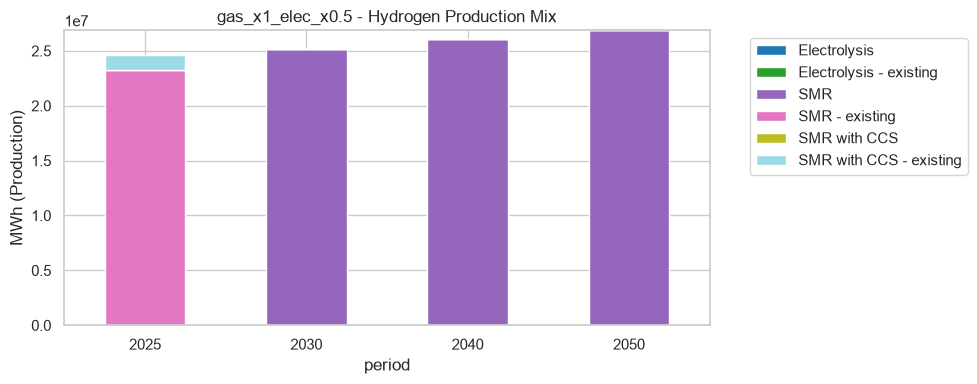

In [16]:
# Hydrogen production mix vizualisation per scenario (no carbon pricing)# 

import pypsa
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_dir = Path("results/final_results") # or Path("results/gas_tests")

for file_path in results_dir.glob("*.nc"):
    try:
        scen = pypsa.Network(file_path)
        scen.name = file_path.stem
        
        fig, ax = plt.subplots(1, 1, figsize=(10, 4))
        
        try:
            df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
        except Exception:
            df = scen.statistics.energy_balance(bus_carrier='hydrogen')
            
        df = df.set_index(df.index.get_level_values(1)).T
        
        # Filter to keep ONLY positive values (production/supply sources)
        df_positive = df.clip(lower=0)
        df_positive = df_positive.loc[:, (df_positive != 0).any(axis=0)]
        
        df_positive.plot(kind='bar', stacked=True, rot=0, colormap="tab20", ax=ax)
        ax.set_ylabel('MWh (Production)')
        ax.set_title(f"{scen.name} - Hydrogen Production Mix")
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        
        fig.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Could not plot {file_path.name}: {e}")